In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Load both leagues
df_d1 = pd.read_csv("Bundesliga1_Cleaned.csv")
df_d2 = pd.read_csv("Bundesliga2_Cleaned.csv")

# Add H2H index if missing
for df in [df_d1, df_d2]:
    df["H2H_Index"] = (
        df["H2H_HomeWins"] - df["H2H_AwayWins"]
    )



In [2]:
exclude = [
    "FTR", "FTHG", "FTAG",
    "HTHG", "HTAG", "HTR",
    "HS", "AS", "HST", "AST",
    "HC", "AC", "HF", "AF",
    "HY", "AY", "HR", "AR",
    "HomePoints", "AwayPoints",
    "HT_GoalDifference",
    "Season", "Matchday"
]

all_features = [
    col for col in df_d1.select_dtypes(include="number").columns
    if col not in exclude and col in df_d2.columns
]

print("Total features:", len(all_features))

for feature in all_features:
    print(feature)

Total features: 43
Home_Last5Points
Home_Last5AvgGoalsFor
Home_Last5AvgGoalsAgainst
Home_Last5AvgShotsFor
Home_Last5AvgShotsAgainst
Home_Last5AvgShotsOnTargetFor
Home_Last5AvgShotsOnTargetAgainst
Home_Last5AvgCornersFor
Home_Last5AvgCornersAgainst
Home_Last5AvgFoulsFor
Home_Last5AvgFoulsAgainst
Home_Last5AvgYellowCardsFor
Home_Last5AvgYellowCardsAgainst
Home_Last5AvgRedCardsFor
Home_Last5AvgRedCardsAgainst
Away_Last5Points
Away_Last5AvgGoalsFor
Away_Last5AvgGoalsAgainst
Away_Last5AvgShotsFor
Away_Last5AvgShotsAgainst
Away_Last5AvgShotsOnTargetFor
Away_Last5AvgShotsOnTargetAgainst
Away_Last5AvgCornersFor
Away_Last5AvgCornersAgainst
Away_Last5AvgFoulsFor
Away_Last5AvgFoulsAgainst
Away_Last5AvgYellowCardsFor
Away_Last5AvgYellowCardsAgainst
Away_Last5AvgRedCardsFor
Away_Last5AvgRedCardsAgainst
Home_Prev5SeasonAvgPPG
Home_Prev5SeasonAvgPoints
Home_PrevSeasonsAvailable
Away_Prev5SeasonAvgPPG
Away_Prev5SeasonAvgPoints
Away_PrevSeasonsAvailable
H2H_HomeWins
H2H_AwayWins
H2H_Draws
H2H_Matches
H

In [3]:
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def beam_feature_selection(
    df, features, league_name,
    beam_width=10,
    scoring="accuracy"
):

    y = df["FTR"]

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            C=1.0
        ))
    ])

    beam = [tuple()]
    results = []
    evaluated = set()

    start = time.time()

    for step in range(1, len(features) + 1):

        candidates = set()

        # Expand all top 10 combinations
        for subset in beam:
            for feature in features:

                if feature not in subset:
                    candidate = tuple(
                        sorted(subset + (feature,))
                    )

                    if candidate not in evaluated:
                        candidates.add(candidate)

        step_results = []

        print(
            f"\n{league_name} | Step {step}/{len(features)}"
            f" | Testing {len(candidates)} combinations",
            flush=True
        )

        for candidate in sorted(candidates):

            scores = cross_validate(
                pipeline,
                df[list(candidate)],
                y,
                cv=cv,
                scoring={
                    "accuracy": "accuracy",
                    "f1_macro": "f1_macro"
                },
                n_jobs=-1
            )

            accuracy = scores["test_accuracy"].mean()
            macro_f1 = scores["test_f1_macro"].mean()

            score = (
                accuracy if scoring == "accuracy"
                else macro_f1
            )

            row = {
                "Number of Features": step,
                "Features": candidate,
                "Accuracy": accuracy,
                "Macro F1": macro_f1,
                "Selection Score": score
            }

            step_results.append(row)
            results.append(row)
            evaluated.add(candidate)

        # Keep the 10 best combinations
        step_results.sort(
            key=lambda x: x["Selection Score"],
            reverse=True
        )

        beam = [
            row["Features"]
            for row in step_results[:beam_width]
        ]

        best = step_results[0]

        print(f"Best Accuracy: {best['Accuracy']:.4f}")
        print(f"Macro F1: {best['Macro F1']:.4f}")
        print(f"Total evaluated: {len(evaluated)}")
        print(f"Elapsed: {(time.time()-start)/60:.2f} minutes",
              flush=True)

        # Save progress after every step
        pd.DataFrame(results).to_csv(
            f"{league_name}_beam_results.csv",
            index=False
        )

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        "Selection Score",
        ascending=False
    ).reset_index(drop=True)

    best = results_df.iloc[0]

    print(f"\n===== {league_name} BEST COMBINATION =====")
    print("Accuracy:", best["Accuracy"])
    print("Macro F1:", best["Macro F1"])
    print("Number of features:", best["Number of Features"])

    for feature in best["Features"]:
        print(feature)

    return results_df, list(best["Features"])

In [4]:
beam_results_d1, beam_features_d1 = beam_feature_selection(
    df_d1,
    all_features,
    "Bundesliga_1",
    beam_width=10,
    scoring="accuracy"
)

beam_results_d2, beam_features_d2 = beam_feature_selection(
    df_d2,
    all_features,
    "Bundesliga_2",
    beam_width=10,
    scoring="accuracy"
)


Bundesliga_1 | Step 1/43 | Testing 43 combinations
Best Accuracy: 0.4789
Macro F1: 0.3429
Total evaluated: 43
Elapsed: 0.39 minutes

Bundesliga_1 | Step 2/43 | Testing 375 combinations
Best Accuracy: 0.4986
Macro F1: 0.3671
Total evaluated: 418
Elapsed: 0.73 minutes

Bundesliga_1 | Step 3/43 | Testing 398 combinations
Best Accuracy: 0.5144
Macro F1: 0.3799
Total evaluated: 816
Elapsed: 1.11 minutes

Bundesliga_1 | Step 4/43 | Testing 387 combinations
Best Accuracy: 0.5192
Macro F1: 0.3837
Total evaluated: 1203
Elapsed: 1.48 minutes

Bundesliga_1 | Step 5/43 | Testing 379 combinations
Best Accuracy: 0.5263
Macro F1: 0.3912
Total evaluated: 1582
Elapsed: 1.84 minutes

Bundesliga_1 | Step 6/43 | Testing 372 combinations
Best Accuracy: 0.5273
Macro F1: 0.3916
Total evaluated: 1954
Elapsed: 2.19 minutes

Bundesliga_1 | Step 7/43 | Testing 354 combinations
Best Accuracy: 0.5307
Macro F1: 0.3948
Total evaluated: 2308
Elapsed: 2.51 minutes

Bundesliga_1 | Step 8/43 | Testing 338 combinations


In [5]:
print("===== Bundesliga 1 =====")
print("Number of features:", len(beam_features_d1))

for feature in beam_features_d1:
    print(feature)

print("\n===== Bundesliga 2 =====")
print("Number of features:", len(beam_features_d2))

for feature in beam_features_d2:
    print(feature)

===== Bundesliga 1 =====
Number of features: 14
Away_Last5AvgCornersAgainst
Away_Last5AvgFoulsAgainst
Away_Last5AvgRedCardsFor
Away_Last5AvgShotsOnTargetAgainst
Away_Last5AvgShotsOnTargetFor
Away_Last5AvgYellowCardsAgainst
H2H_Draws
H2H_Index
Home_Last5AvgGoalsFor
Home_Last5AvgRedCardsAgainst
Home_Last5AvgShotsFor
Home_Last5AvgShotsOnTargetAgainst
Home_Last5AvgYellowCardsAgainst
Home_Last5Points

===== Bundesliga 2 =====
Number of features: 21
Away_Last5AvgCornersAgainst
Away_Last5AvgFoulsAgainst
Away_Last5AvgFoulsFor
Away_Last5AvgGoalsFor
Away_Last5AvgRedCardsAgainst
Away_Last5AvgShotsAgainst
Away_Last5AvgShotsOnTargetFor
Away_Last5AvgYellowCardsAgainst
Away_Last5AvgYellowCardsFor
Away_PrevSeasonsAvailable
Away_RestDays
H2H_HomeWins
H2H_Index
Home_Last5AvgGoalsFor
Home_Last5AvgShotsFor
Home_Last5AvgShotsOnTargetAgainst
Home_Last5AvgShotsOnTargetFor
Home_Prev5SeasonAvgPPG
Home_Prev5SeasonAvgPoints
Home_PrevSeasonsAvailable
Home_RestDays


In [6]:
display(beam_results_d1.head(10))
display(beam_results_d2.head(10))

,Number of Features,Features,Accuracy,Macro F1,Selection Score
0,14,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.536404,0.406886,0.536404
1,13,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.536403,0.405136,0.536403
2,15,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535926,0.406174,0.535926
3,14,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535926,0.406174,0.535926
4,14,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535926,0.405786,0.535926
5,14,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535926,0.406174,0.535926
6,16,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535448,0.405972,0.535448
7,14,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535447,0.404218,0.535447
8,15,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535446,0.405584,0.535446
9,15,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.535446,0.405584,0.535446


,Number of Features,Features,Accuracy,Macro F1,Selection Score
0,21,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.476058,0.369203,0.476058
1,21,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.475580,0.368637,0.475580
2,22,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.475106,0.369268,0.475106
3,21,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.475106,0.369268,0.475106
4,22,"(Away_Last5AvgFoulsAgainst, Away_Last5AvgFouls...",0.475102,0.372081,0.475102
5,20,"(Away_Last5AvgFoulsAgainst, Away_Last5AvgFouls...",0.475101,0.368377,0.475101
6,22,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.475101,0.368364,0.475101
7,22,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.475100,0.370490,0.475100
8,20,"(Away_Last5AvgCornersAgainst, Away_Last5AvgFou...",0.474625,0.366924,0.474625
9,21,"(Away_Last5AvgFoulsAgainst, Away_Last5AvgFouls...",0.474624,0.371872,0.474624


In [7]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

def run_softmax_weighted(df, features, league_name, draw_weight):

    X = df[features]
    y = df["FTR"]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            C=1.0
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # Get cross-validated probabilities
    probabilities = cross_val_predict(
        pipeline,
        X,
        y,
        cv=cv,
        method="predict_proba"
    )

    # Classes ordered A, D, H
    classes = np.array(["A", "D", "H"])

    # Increase draw score
    adjusted = probabilities.copy()
    adjusted[:, 1] *= draw_weight

    # Final predictions
    predictions = classes[np.argmax(adjusted, axis=1)]

    print(f"\n===== {league_name} =====")
    print(f"Draw Weight: {draw_weight}")
    print(f"Accuracy: {accuracy_score(y, predictions):.4f}")
    print(f"Macro F1: {f1_score(y, predictions, average='macro'):.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y, predictions,
        labels=["H", "D", "A"],
        target_names=["Home Win", "Draw", "Away Win"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y,
        predictions,
        labels=["H", "D", "A"],
        display_labels=["Home", "Draw", "Away"],
        cmap="Blues"
    )

    plt.title(f"{league_name} - Softmax (Draw Weight {draw_weight})")
    plt.show()




===== Bundesliga 1 =====
Draw Weight: 1
Accuracy: 0.5364
Macro F1: 0.4072

Classification Report:
              precision    recall  f1-score   support

    Home Win       0.55      0.80      0.65       915
        Draw       0.47      0.01      0.03       512
    Away Win       0.52      0.57      0.55       661

    accuracy                           0.54      2088
   macro avg       0.51      0.46      0.41      2088
weighted avg       0.52      0.54      0.46      2088



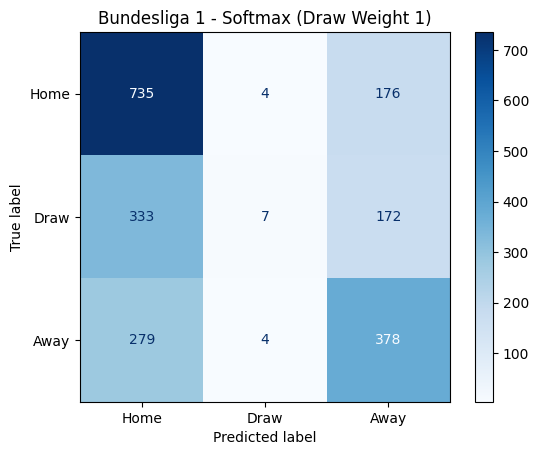


===== Bundesliga 2 =====
Draw Weight: 1
Accuracy: 0.4761
Macro F1: 0.3693

Classification Report:
              precision    recall  f1-score   support

    Home Win       0.49      0.82      0.61       903
        Draw       0.44      0.06      0.10       553
    Away Win       0.45      0.36      0.40       632

    accuracy                           0.48      2088
   macro avg       0.46      0.41      0.37      2088
weighted avg       0.46      0.48      0.41      2088



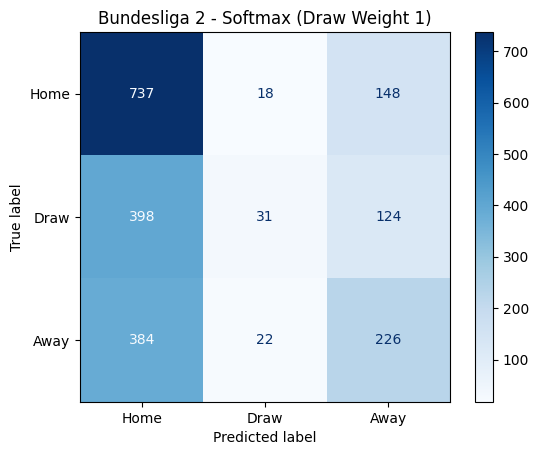

In [18]:
run_softmax_weighted(
    df_d1,
    beam_features_d1,
    "Bundesliga 1",
    draw_weight=1
)

run_softmax_weighted(
    df_d2,
    beam_features_d2,
    "Bundesliga 2",
    draw_weight=1
)

#Majority baseline 43% for both

In [12]:
for df, league in [(df_d1, "Bundesliga 1"),
                   (df_d2, "Bundesliga 2")]:

    y = df["FTR"]

    print(f"\n===== {league} =====")
    print(y.value_counts())
    print("\nOutcome percentages:")
    print(y.value_counts(normalize=True) * 100)

    print("\nMajority class:", y.mode()[0])
    print(f"Majority baseline: {y.value_counts(normalize=True).max():.2%}")


===== Bundesliga 1 =====
FTR
H    915
A    661
D    512
Name: count, dtype: int64

Outcome percentages:
FTR
H    43.821839
A    31.657088
D    24.521073
Name: proportion, dtype: float64

Majority class: H
Majority baseline: 43.82%

===== Bundesliga 2 =====
FTR
H    903
A    632
D    553
Name: count, dtype: int64

Outcome percentages:
FTR
H    43.247126
A    30.268199
D    26.484674
Name: proportion, dtype: float64

Majority class: H
Majority baseline: 43.25%


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def get_feature_importance(df, features, league_name):

    X = df[features]
    y = df["FTR"]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            C=1.0
        ))
    ])

    pipeline.fit(X, y)

    model = pipeline.named_steps["model"]

    coefficients = model.coef_

    importance = np.mean(np.abs(coefficients), axis=0)

    importance_df = pd.DataFrame({
        "Feature": features,
        "Importance": importance
    })

    importance_df["Importance (%)"] = (
        importance / importance.sum() * 100
    )

    importance_df = importance_df.sort_values(
        "Importance", ascending=False
    ).reset_index(drop=True)

    print(f"\n===== {league_name} =====")
    display(importance_df)

    plt.figure(figsize=(10, max(5, len(features) * 0.35)))

    plt.barh(
        importance_df["Feature"],
        importance_df["Importance (%)"]
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Relative Feature Importance (%)")
    plt.title(f"{league_name} - Softmax Feature Importance")
    plt.tight_layout()
    plt.show()

    return importance_df, pipeline


===== Bundesliga 1 =====


,Feature,Importance,Importance (%)
0,H2H_Index,0.116663,12.144972
1,Away_Last5AvgCornersAgainst,0.108298,11.274120
2,Away_Last5AvgShotsOnTargetFor,0.102661,10.687296
3,Home_Last5AvgShotsFor,0.100524,10.464858
4,Away_Last5AvgShotsOnTargetAgainst,0.092497,9.629259
5,Home_Last5AvgGoalsFor,0.082924,8.632693
6,Home_Last5Points,0.069877,7.274417
7,Away_Last5AvgFoulsAgainst,0.067109,6.986226
8,Away_Last5AvgYellowCardsAgainst,0.062816,6.539395
9,Home_Last5AvgRedCardsAgainst,0.061920,6.446050


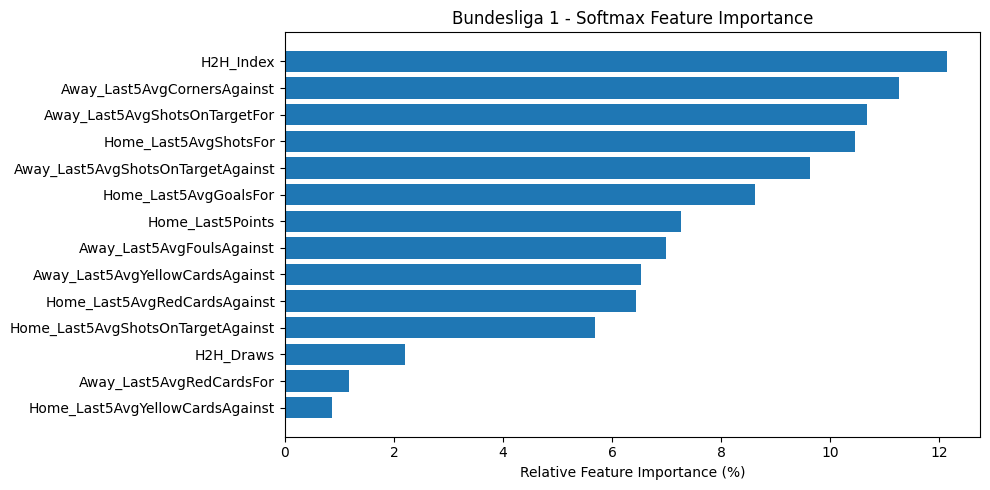


===== Bundesliga 2 =====


,Feature,Importance,Importance (%)
0,Home_Last5AvgShotsFor,0.103463,10.388053
1,Home_PrevSeasonsAvailable,0.092813,9.318775
2,Away_Last5AvgShotsOnTargetFor,0.075123,7.542687
3,Away_Last5AvgFoulsAgainst,0.071134,7.142159
4,Away_Last5AvgShotsAgainst,0.060565,6.080999
5,Away_RestDays,0.056049,5.627583
6,Away_Last5AvgYellowCardsAgainst,0.051064,5.127076
7,Away_Last5AvgFoulsFor,0.050936,5.114163
8,Away_PrevSeasonsAvailable,0.050222,5.042504
9,Home_Last5AvgShotsOnTargetAgainst,0.048385,4.857996


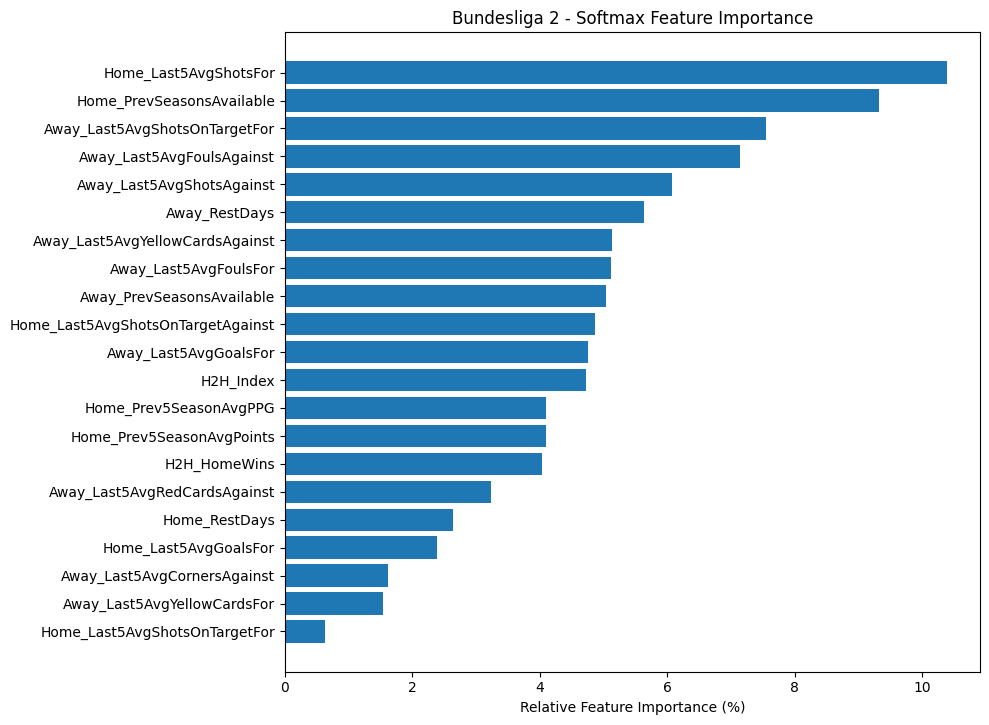

In [21]:
importance_d1, model_d1 = get_feature_importance(
    df_d1,
    beam_features_d1,
    "Bundesliga 1"
)

importance_d2, model_d2 = get_feature_importance(
    df_d2,
    beam_features_d2,
    "Bundesliga 2"
)